# 03　ASK：一致性判定

`02_ASK_demod` 已经把 ASK4 解出来，本册只做一件事：**拿实测指标对照门限**，给出 PASS / FAIL。

| 判据 | 门限 | 离线仿真值 |
|---|---|---|
| 误码 | 0 | 0 |
| EVM max | ≤ 8% | 1.3~3.6% |
| 判决余量 min | ≥ 0.85 | 0.91~0.92 |

门限由仿真留 2~3 倍余量：板上多了 DAC/ADC 量化、环回损耗和时钟抖动，指标会变差，
但不该跨一个量级。门限写在 `mod_cases.LIM`，改动只有一处。

## 1　复算并判定

In [1]:
import os
import sys

# 库目录：mod_dsp / mod_cases / 全部 .npz 都在这里（notebook 目录只放 .ipynb）
LIB  = "/home/xilinx/modulation"
QPSK = "/home/xilinx/qpsk"        # qpsk_dsp / qpsk_hw / qpsk_init / run_test
for _p in (LIB, QPSK):
    if os.path.isdir(_p) and _p not in sys.path:
        sys.path.insert(0, _p)

CASE = "ASK4"
N_TX, N_DEMOD, N_VERIFY = 1, 2, 3
# 抓包（第 N_TX 册写，第 N_DEMOD / N_VERIFY 册读）与指标（第 N_DEMOD 册写）
CAP_NPZ = os.path.join(LIB, "mod_%02d_%s.npz" % (N_TX, CASE))
DEM_NPZ = os.path.join(LIB, "mod_%02d_%s.npz" % (N_DEMOD, CASE))

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

%matplotlib inline

import mod_dsp as M
import mod_cases as C

# font.family 列表触发逐字形回退（mpl≥3.6）：拉丁取自 DejaVu，中文取本机
# 已有的 CJK 字体（板上 Droid Sans Fallback / Windows 雅黑）。只列**已安装**的
# 名字，否则 matplotlib 会为每个字形打一行 findfont 警告（实测上千行）。
import matplotlib.font_manager as _fm
_avail = {f.name for f in _fm.fontManager.ttflist}
_fam = [n for n in ("DejaVu Sans", "Microsoft YaHei", "Noto Sans CJK SC",
                    "WenQuanYi Zen Hei", "Droid Sans Fallback") if n in _avail]
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 9,
    "axes.titlesize": 10, "legend.fontsize": 8,
    "font.family": _fam or ["DejaVu Sans"],
    "axes.unicode_minus": False,
})

SPEC = next(s for s in (C.DIGITAL_CASES + C.ANALOG_CASES) if s["name"] == CASE)
KIND = "digital" if "scheme" in SPEC else "analog"

print("mod_dsp  :", M.__file__)
print("mod_cases:", C.__file__)
print("案例     : %s（%s）" % (CASE, "数字" if KIND == "digital" else "模拟"))
print("库目录   :", LIB)
print("抓包文件 :", CAP_NPZ)

mod_dsp  : /home/xilinx/modulation/mod_dsp.py
mod_cases: /home/xilinx/modulation/mod_cases.py
案例     : ASK4（数字）
库目录   : /home/xilinx/modulation
抓包文件 : /home/xilinx/modulation/mod_01_ASK4.npz


In [2]:
if not os.path.exists(CAP_NPZ):
    raise FileNotFoundError("缺 %s —— 先跑 %02d_%s_tx_rx.ipynb"
                            % (CAP_NPZ, N_TX, CASE))

r = C.load_and_demod(CAP_NPZ)
ok, det = C.verdict(r)
m = r["metrics"]

print("%-6s %-4s %-5s  %s"
      % (CASE, "数字" if KIND == "digital" else "模拟",
         "PASS" if ok else "FAIL", det))
print()
if KIND == "digital":
    rows = [("误码", "%d / %d" % (m["err"], m["tot"]), "0",
             m["err"] == 0),
            ("EVM max", "%.2f %%" % m["evm_max"], "≤ %.1f %%" % C.LIM["evm_max"],
             m["evm_max"] <= C.LIM["evm_max"]),
            ("判决余量 min", "%.3f" % m["margin_min"],
             "≥ %.2f" % C.LIM["margin_min"],
             m["margin_min"] >= C.LIM["margin_min"]),
            ("残余频偏中位", "%+.0f Hz" % m["cfo"], "±800 Hz",
             abs(m["cfo"]) < 800.0)]
else:
    ratio = C.ratio_of(r)
    rows = [("|corr|", "%.4f" % abs(m["corr"]),
             "≥ %.2f" % C.LIM["corr_min"],
             abs(m["corr"]) >= C.LIM["corr_min"]),
            ("归一化 RMSE", "%.1f %%" % (m["rmse"] * 100),
             "≤ %.0f %%" % (C.LIM["rmse_max"] * 100),
             m["rmse"] <= C.LIM["rmse_max"]),
            ("%s 实测/设定" % ("μ" if r["spec"]["kind"] == "am" else "Δf"),
             "%.3f" % ratio, "1 ± %.2f" % C.LIM["ratio_tol"],
             abs(ratio - 1) <= C.LIM["ratio_tol"])]
    if r["spec"]["kind"] == "fm":
        rows.append(("幅度纹波", "%.1f %%" % (m["ripple"] * 100),
                     "≤ %.0f %%" % (C.LIM["ripple_max"] * 100),
                     m["ripple"] <= C.LIM["ripple_max"]))

print("  %-16s %-12s %-12s %s" % ("判据", "实测", "门限", "结果"))
print("  " + "-" * 56)
for name, got, lim, good in rows:
    print("  %-16s %-12s %-12s %s" % (name, got, lim, "PASS" if good else "FAIL"))

ASK4   数字   PASS   BER 0/9216，EVM max 2.68%（≤8.0），余量 min 0.925（≥0.85）

  判据               实测           门限           结果
  --------------------------------------------------------
  误码               0 / 9216     0            PASS
  EVM max          2.68 %       ≤ 8.0 %      PASS
  判决余量 min         0.925        ≥ 0.85       PASS
  残余频偏中位           -31 Hz       ±800 Hz      PASS


**应该看到**：第一行 `PASS`，下面每一行都是 `PASS`。

若有 FAIL，先看是哪一条：误码 = 同步或星座映射；EVM 偏大 = 环回衰减 / ADC 饱和；
余量小但 BER 为 0 = 星座压缩（增益不匹配）；相关系数低 = 模拟链路的下变频或门控问题。

## 2　指标图

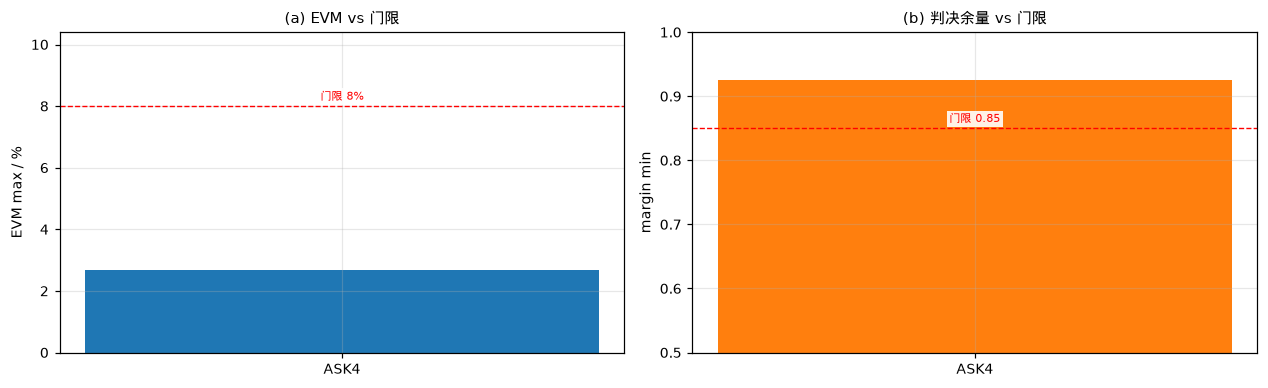

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11.6, 3.6))


def _note(a, y, text):
    """把门限文字标在虚线上方居中，替代图例（图例框会压在柱子上）。"""
    a.annotate(text, xy=(0.5, y), xycoords=("axes fraction", "data"),
               xytext=(0, 2.5), textcoords="offset points",
               ha="center", va="bottom", fontsize=7, color="r",
               bbox=dict(fc="white", ec="none", pad=1.5, alpha=0.9))


ax[0].bar([0], [m["evm_max"]], width=0.45)
ax[0].axhline(C.LIM["evm_max"], color="r", ls="--", lw=0.9)
ax[0].set_ylim(0, 1.3 * C.LIM["evm_max"])
ax[0].set_xticks([0]); ax[0].set_xticklabels([CASE])
ax[0].set_ylabel("EVM max / %")
ax[0].set_title("(a) EVM vs 门限")
_note(ax[0], C.LIM["evm_max"], "门限 %.0f%%" % C.LIM["evm_max"])

ax[1].bar([0], [m["margin_min"]], width=0.45, color="C1")
ax[1].axhline(C.LIM["margin_min"], color="r", ls="--", lw=0.9)
ax[1].set_ylim(0.5, 1.0)
ax[1].set_xticks([0]); ax[1].set_xticklabels([CASE])
ax[1].set_ylabel("margin min")
ax[1].set_title("(b) 判决余量 vs 门限")
_note(ax[1], C.LIM["margin_min"], "门限 %.2f" % C.LIM["margin_min"])

plt.tight_layout()
plt.show()

## 3　结论与排错

ASK4（数字） 的判定全 PASS 说明：帧结构、同步代码与 QPSK 完全一致，只有星座映射不同 —— 说明这套接收链对任意 PSK / QAM / ASK 阶数都成立，差别只剩下 EVM 与判决余量的余量。

| 症状 | 检查顺序 |
|---|---|
| BER 全错 | 位流不是 128 位版本（TX 保持段）或 ADC 只回 I 通道 |
| EVM 偏大但 BER=0 | 环回衰减过大、ADC 接近饱和 |
| 余量 < 0.85 | 星座压缩：检查发射峰值与环回增益 |
| 频偏中位 > 1 kHz | LMK / SYSREF；回 `00_ASK_init` 第 2 节重跑时钟 |